<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/eda_esda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multidimensional poverty in Bolivia: exploratory and spatial data analysis

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

This notebook combines classical exploratory data analysis (EDA) with exploratory spatial data analysis (ESDA) for Bolivia's 339 municipalities. The outcome is the **Multidimensional Poverty Index** (`sdg1_2_mpi`, 2012), which runs from 0 to 1: **higher values mean more poverty**. Night-time lights per capita, population and a set of infrastructure and connectivity indicators are the companions.

1. **Data**: everything is loaded with the `geo4bolivia` package
2. **EDA**: summaries, distributions, department comparisons, population, night-time lights and infrastructure correlates
3. **Maps**: box-plot and Fisher–Jenks classifications
4. **Spatial dependence**: spatial weights, global and local Moran's I, bivariate Moran's I and bivariate LISA
5. **Spatial inequality**: Gini, Theil and its decomposition by department, spatial Gini
6. **Spatial heterogeneity**: a geographically weighted regression of poverty on night-time lights
7. **Summary**

It is a port of DS4Bolivia's *Extended EDA + Spatial Analysis* notebook. The focused notebooks `esda_dependence`, `esda_inequality` and `esda_heterogeneity` go deeper into sections 4–6.

## 0. Setup

In Google Colab the next cell installs the package and the spatial-analysis libraries that Colab lacks. Locally, `uv sync` has installed them already, so nothing is installed.

In [1]:
import importlib.util

missing = [m for m in ["geo4bolivia", "mapclassify", "libpysal", "esda", "splot", "inequality", "mgwr"]
           if importlib.util.find_spec(m) is None]
if missing:
    !pip install -q {" ".join(missing)}

In [2]:
import sys
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import plotly.express as px
import plotly.io as pio

import mapclassify as mc
from libpysal import weights
from esda.moran import Moran, Moran_Local, Moran_BV, Moran_Local_BV
from splot.esda import moran_scatterplot, lisa_cluster
from splot.libpysal import plot_spatial_weights
import inequality
from inequality.gini import Gini_Spatial
from mgwr.gwr import GWR
from mgwr.sel_bw import Sel_BW

import geo4bolivia as geo

warnings.filterwarnings("ignore")
np.random.seed(12345)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
# Plotly: Colab's own renderer there; elsewhere load plotly.js from its CDN to keep the file small
pio.renderers.default = "colab" if "google.colab" in sys.modules else "notebook_connected"

## 1. Data

Four pieces, all at the municipality scale and keyed by `geo_id`:

| Variable | Dataset | Year | Meaning |
| --- | --- | --- | --- |
| `sdg1_2_mpi` | `sdg01` | 2012 | Multidimensional Poverty Index (0–1, higher = poorer) |
| `ln_t400NTLpc` | `ntl` | 2012 | Hodrick–Prescott trend of the log of night-time lights per capita |
| `pop` | `pop` | 2012 | Gridded population (WorldPop) |
| infrastructure and connectivity | `sdg06`, `sdg07`, `sdg09`, ... | own year | see section 2.5 |

`geo.load(..., geometry=True)` returns a GeoDataFrame with names and boundaries; `geo.combine` puts night-time lights and population on one panel.

In [3]:
gdf = geo.load("sdg01", variables="sdg1_2_mpi", years=2012, geometry=True)
ntl_pop = geo.combine(["ntl", "pop"], scale="municipality", years=2012)
gdf = gdf.merge(ntl_pop[["geo_id", "ln_t400NTLpc", "pop"]], on="geo_id")

# Department of each municipality, from the units table
units = geo.units("municipality")[["geo_id", "department_id"]]
departments = geo.units("department").set_index("geo_id")["name"]
gdf = gdf.merge(units, on="geo_id")
gdf["department"] = gdf["department_id"].map(departments)
gdf["ln_pop"] = np.log(gdf["pop"])

# Work in the observatory's equal-area projection (metres)
gdf = gdf.to_crs(geo.config()["equal_area_crs"])
dep_lines = geo.boundaries("department").to_crs(gdf.crs)

print(gdf.shape)
gdf[["geo_id", "name", "department", "sdg1_2_mpi", "ln_t400NTLpc", "pop"]].head()

(339, 10)


,geo_id,name,department,sdg1_2_mpi,ln_t400NTLpc,pop
0,BO-01-01-01,Azurduy,Chuquisaca,0.440,11.048312,10927.5350
1,BO-01-01-02,Tarvita,Chuquisaca,0.380,12.329279,14207.9030
2,BO-01-02-01,Villa Serrano,Chuquisaca,0.199,12.815315,11159.8340
3,BO-01-03-01,Huacareta,Chuquisaca,0.261,12.018971,8394.6611
4,BO-01-03-02,Monteagudo,Chuquisaca,0.166,14.603350,24266.3730


The SDG Atlas is published as one dataset per goal (`sdg01` to `sdg17`), and each indicator refers to its own year. A cross-section of every indicator stacks the goals and keeps each municipality's value:

In [4]:
goals = [d for d in geo.datasets()["dataset"] if d.startswith("sdg")]
sdg_long = pd.concat([geo.load(d) for d in goals])
sdg = sdg_long.groupby("geo_id").first()
sdg_dict = pd.concat([geo.dictionary(d) for d in goals]).drop_duplicates("variable").set_index("variable")
ref_year = {v: int(sdg_long.loc[sdg_long[v].notna(), "year"].min()) for v in sdg.columns if v != "year"}
labels = sdg_dict["label"].to_dict()
labels.update({"sdg1_2_mpi": "Multidimensional poverty (MPI)", "ln_t400NTLpc": "Log NTL per capita (trend)",
               "ln_pop": "Log population"})
print(sdg.shape)

(339, 81)


## 2. Exploratory data analysis

### 2.1 Descriptive statistics

What do we know about the centre and spread of poverty?

In [5]:
gdf[["sdg1_2_mpi", "ln_t400NTLpc", "pop"]].describe().round(3)

,sdg1_2_mpi,ln_t400NTLpc,pop
count,339.000,339.000,339.000
mean,0.179,13.033,29725.213
std,0.098,1.672,106567.221
min,0.007,0.856,518.916
25%,0.105,12.050,5951.324
50%,0.171,13.118,10979.984
75%,0.241,14.268,20057.188
max,0.520,17.071,1429553.000


In [6]:
cols = ["name", "department", "sdg1_2_mpi", "ln_t400NTLpc", "pop"]
ranked = gdf[cols].sort_values("sdg1_2_mpi", ascending=False).reset_index(drop=True)
print("Poorest 10 municipalities")
display(ranked.head(10).round(3))
print("Least poor 10 municipalities")
display(ranked.tail(10).round(3))

Poorest 10 municipalities


,name,department,sdg1_2_mpi,ln_t400NTLpc,pop
0,El Sena,Pando,0.520,10.160,8187.162
1,San Pedro,Pando,0.508,12.545,3383.919
2,Poroma,Chuquisaca,0.454,9.194,24100.660
3,Azurduy,Chuquisaca,0.440,11.048,10927.535
4,El Choro,Oruro,0.405,12.388,7638.146
5,San Pedro de Buena Vista,Potosí,0.403,10.943,31481.523
6,Incahuasi,Chuquisaca,0.394,11.033,16459.486
7,Tacobamba,Potosí,0.391,12.507,13208.288
8,Vila Vila,Cochabamba,0.386,12.204,5434.199
9,Alalay,Cochabamba,0.386,11.985,3492.443


Least poor 10 municipalities


,name,department,sdg1_2_mpi,ln_t400NTLpc,pop
329,Potosí,Potosí,0.029,15.072,185692.470
330,Cliza,Cochabamba,0.028,15.307,21223.469
331,El Alto,La Paz,0.027,15.161,820031.130
332,Quillacollo,Cochabamba,0.026,15.373,138671.090
333,Tarija,Tarija,0.026,14.780,201887.130
334,Punata,Cochabamba,0.023,14.794,27142.094
335,Santa Cruz de la Sierra,Santa Cruz,0.012,14.949,1429553.000
336,Huachacalla,Oruro,0.010,14.726,848.686
337,La Paz,La Paz,0.008,14.691,782052.940
338,Colcapirhua,Cochabamba,0.007,15.182,54299.598


The average municipality has an MPI of 0.179 (median 0.171, standard deviation 0.098), with values from 0.007 in Colcapirhua (Cochabamba) to 0.520 in El Sena (Pando). The two poorest municipalities are in Pando; the rest of the top ten are rural municipalities of Chuquisaca, Potosí, Oruro and Cochabamba. The least poor are the large cities and their metropolitan areas (La Paz, El Alto, Santa Cruz de la Sierra, Tarija, Potosí, Quillacollo, Colcapirhua), small towns of the Cochabamba valley (Cliza, Punata) and Huachacalla, a very small Oruro municipality of about 850 people.

Night-time lights have one extreme value: Mojinete (Potosí) has a log of 0.86, against 5.47 for the next darkest municipality.

How do departments compare? The table gives the simple mean over municipalities and, with `geo.aggregate`, the population-weighted mean (the poverty of the average resident).

In [7]:
by_dep = gdf.groupby("department")["sdg1_2_mpi"].describe().round(3)

# Population-weighted department means with geo.aggregate
mpi_panel = geo.load("sdg01", variables="sdg1_2_mpi", years=2012)
dep_w = geo.aggregate(mpi_panel, to="department", rules={"sdg1_2_mpi": "weighted_mean:pop"},
                      weights=geo.load("pop"))
dep_w["department"] = dep_w["geo_id"].map(departments)
by_dep["pop_weighted_mean"] = dep_w.set_index("department")["sdg1_2_mpi"].round(3)
by_dep.sort_values("mean", ascending=False)

,count,mean,std,min,25%,50%,75%,max,pop_weighted_mean
department,,,,,,,,,
Pando,15.0,0.322,0.123,0.057,0.268,0.362,0.370,0.520,0.222
Chuquisaca,29.0,0.260,0.095,0.046,0.199,0.249,0.302,0.454,0.181
Potosí,40.0,0.204,0.101,0.029,0.136,0.194,0.264,0.403,0.166
Beni,19.0,0.196,0.073,0.058,0.158,0.183,0.231,0.371,0.158
Cochabamba,47.0,0.175,0.106,0.007,0.080,0.186,0.246,0.386,0.099
Oruro,35.0,0.172,0.085,0.010,0.118,0.165,0.244,0.405,0.094
La Paz,87.0,0.166,0.072,0.008,0.118,0.164,0.213,0.381,0.077
Santa Cruz,56.0,0.122,0.063,0.012,0.070,0.112,0.173,0.280,0.054
Tarija,11.0,0.082,0.042,0.026,0.047,0.097,0.106,0.149,0.052


Pando is the poorest department (mean 0.322, median 0.362), followed by Chuquisaca (0.260) and Potosí (0.204); Tarija (0.082) and Santa Cruz (0.122) are the least poor. Weighting by population lowers every department's figure, often by half (La Paz from 0.166 to 0.077, Cochabamba from 0.175 to 0.099), because the populous municipalities are the least poor. The ranking of departments is the same under both measures.

### 2.2 Distributions and department differences

How is poverty distributed across the 339 municipalities and the 9 departments?

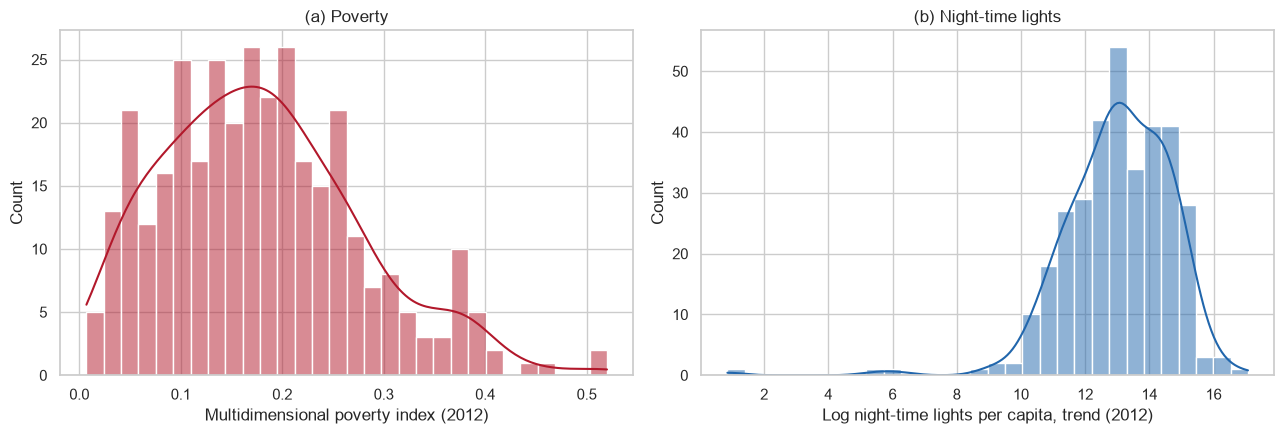

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(gdf["sdg1_2_mpi"], kde=True, bins=30, color="#b2182b", ax=axes[0])
axes[0].set(xlabel="Multidimensional poverty index (2012)", title="(a) Poverty")
sns.histplot(gdf["ln_t400NTLpc"], kde=True, bins=30, color="#2166ac", ax=axes[1])
axes[1].set(xlabel="Log night-time lights per capita, trend (2012)", title="(b) Night-time lights")
plt.tight_layout()
plt.show()

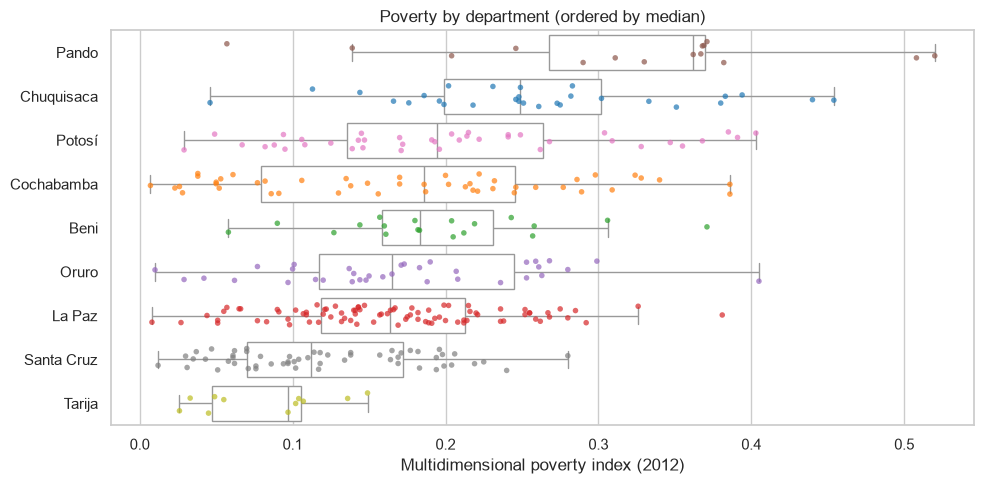

In [9]:
order = gdf.groupby("department")["sdg1_2_mpi"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=gdf, x="sdg1_2_mpi", y="department", order=order, color="white", fliersize=0, ax=ax)
sns.stripplot(data=gdf, x="sdg1_2_mpi", y="department", order=order, hue="department", palette="tab10",
              size=4, alpha=0.7, jitter=0.25, legend=False, ax=ax)
ax.set(xlabel="Multidimensional poverty index (2012)", ylabel="",
       title="Poverty by department (ordered by median)")
plt.tight_layout()
plt.show()

Poverty is moderately right-skewed (mean 0.179 above the median 0.171), with a thin upper tail beyond 0.40. Log night-time lights are left-skewed, with Mojinete and a few very dark municipalities far to the left of the bulk (11–16).

The department boxes overlap widely: the spread *within* departments is large compared with the differences *between* them. Cochabamba alone runs from 0.007 to 0.386. Pando and Chuquisaca stand out at the top, Santa Cruz and Tarija at the bottom.

### 2.3 Population and poverty

Are the most populous municipalities less poor?

In [10]:
fig = px.treemap(gdf.assign(country="Bolivia"), path=["country", "department", "name"], values="pop",
                 color="sdg1_2_mpi", color_continuous_scale="RdBu_r",
                 color_continuous_midpoint=float(gdf["sdg1_2_mpi"].median()),
                 labels={"sdg1_2_mpi": "MPI 2012", "pop": "Population 2012"},
                 title="Municipalities sized by population (2012), coloured by poverty")
fig.update_layout(margin=dict(t=40, l=5, r=5, b=5), height=550)
fig.show()

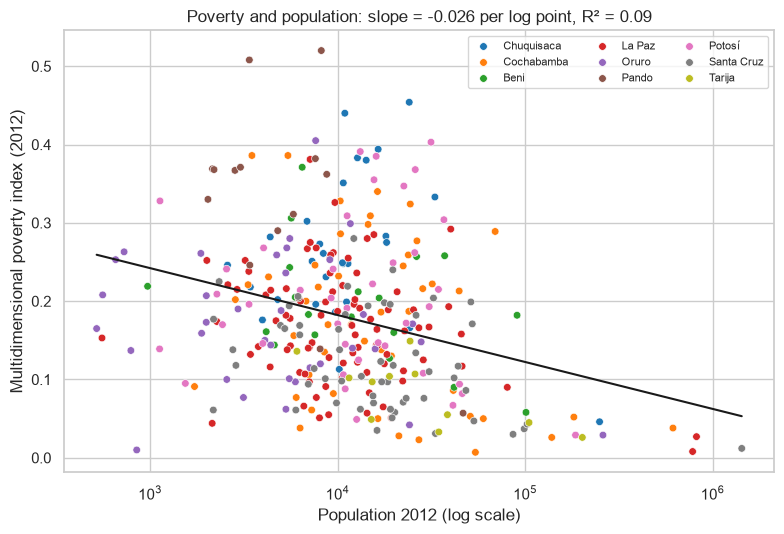

In [11]:
ols_pop = smf.ols("sdg1_2_mpi ~ ln_pop", data=gdf).fit()
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=gdf, x="pop", y="sdg1_2_mpi", hue="department", palette="tab10", s=30, ax=ax)
xs = np.linspace(gdf["ln_pop"].min(), gdf["ln_pop"].max(), 50)
ax.plot(np.exp(xs), ols_pop.params["Intercept"] + ols_pop.params["ln_pop"] * xs, color="k", lw=1.5)
ax.set_xscale("log")
ax.set(xlabel="Population 2012 (log scale)", ylabel="Multidimensional poverty index (2012)",
       title=f"Poverty and population: slope = {ols_pop.params['ln_pop']:.3f} per log point, "
             f"R² = {ols_pop.rsquared:.2f}")
ax.legend(fontsize=8, ncol=3, loc="upper right")
plt.tight_layout()
plt.show()

In the treemap (click a department to zoom in) the largest blocks, the cities of Santa Cruz de la Sierra, El Alto, La Paz and Cochabamba, are low-poverty blue; the poorest municipalities are small blocks.

The regression line confirms a negative but weak association: each additional log point of population goes with an MPI 0.026 lower, and population explains only 9% of the variation. Small municipalities can be very poor or not poor at all.

### 2.4 Night-time lights and poverty

Can night-time lights help us predict poverty?

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.5877      0.035     16.622      0.000       0.518       0.657
ln_t400NTLpc    -0.0314      0.003    -11.654      0.000      -0.037      -0.026
R² = 0.287, n = 339


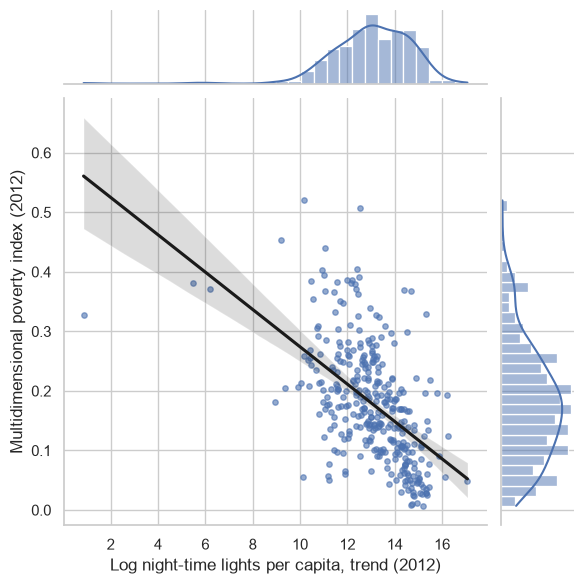

In [12]:
ols_ntl = smf.ols("sdg1_2_mpi ~ ln_t400NTLpc", data=gdf).fit()
print(ols_ntl.summary().tables[1])
print(f"R² = {ols_ntl.rsquared:.3f}, n = {int(ols_ntl.nobs)}")

g = sns.jointplot(data=gdf, x="ln_t400NTLpc", y="sdg1_2_mpi", kind="reg", height=6,
                  scatter_kws=dict(s=15, alpha=0.6), line_kws=dict(color="k"),
                  marginal_kws=dict(bins=30))
g.set_axis_labels("Log night-time lights per capita, trend (2012)", "Multidimensional poverty index (2012)")
plt.show()

How heterogeneous is the relationship across departments?

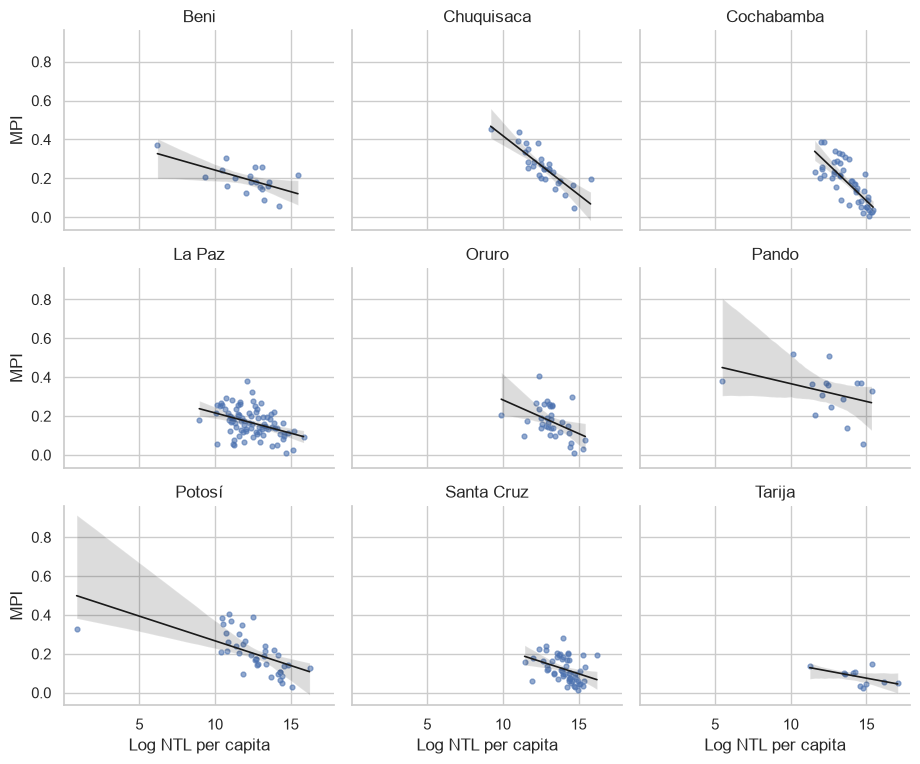

,n,slope,corr
department,,,
Cochabamba,47.0,-0.074,-0.771
Chuquisaca,29.0,-0.061,-0.833
Oruro,35.0,-0.035,-0.445
Potosí,40.0,-0.025,-0.603
Santa Cruz,56.0,-0.025,-0.375
Beni,19.0,-0.022,-0.618
La Paz,87.0,-0.021,-0.403
Pando,15.0,-0.018,-0.358
Tarija,11.0,-0.014,-0.517


In [13]:
fg = sns.lmplot(data=gdf, x="ln_t400NTLpc", y="sdg1_2_mpi", col="department", col_wrap=3,
                col_order=sorted(gdf["department"].unique()), height=2.6, aspect=1.2,
                scatter_kws=dict(s=12, alpha=0.6), line_kws=dict(color="k", lw=1.2))
fg.set_axis_labels("Log NTL per capita", "MPI")
fg.set_titles("{col_name}")
plt.show()

slopes = (gdf.groupby("department")
          .apply(lambda d: pd.Series({"n": len(d),
                                      "slope": smf.ols("sdg1_2_mpi ~ ln_t400NTLpc", data=d).fit().params.iloc[1],
                                      "corr": d["sdg1_2_mpi"].corr(d["ln_t400NTLpc"])}))
          .sort_values("slope").round(3))
slopes

Night-time lights are a much stronger predictor than population: one more log point of lights per capita goes with an MPI 0.031 lower (t = −11.7), and lights alone explain 29% of the variation in poverty. The marginal histograms show the dark outlier, Mojinete, at the far left.

Within every department the slope is negative, but its size varies by a factor of five. It is steepest in Cochabamba (−0.074) and Chuquisaca (−0.061), where the correlations are also strongest (−0.77 and −0.83), and flattest in Tarija (−0.014) and Pando (−0.018). Potosí's line is pulled by Mojinete, the single point at the far left of its panel. Section 6 shows that this heterogeneity is geographic.

### 2.5 Infrastructure and connectivity correlates

Which infrastructure and connectivity indicators move with poverty? From the SDG Atlas cross-section, each at its own reference year:

| Variable | Meaning | Year |
| --- | --- | --- |
| `urbano_2012` | Urbanization rate (%) | 2012 |
| `sdg7_1_ec` | Electricity coverage (% of population) | 2012 |
| `sdg9_c_mnc` | Fixed and mobile network coverage (% of households) | 2012 |
| `sdg9_c_drb` | Radio bases per 1,000 inhabitants | 2016 |
| `sdg9_5_eutf` | Schools with technological floors (%) | 2016 |
| `sdg9_5_cd` | Kuaa computers delivered per 100 school-age children | 2016 |
| `sdg11_2_samt` | Mass-transit seats per 1,000 inhabitants | 2017 |
| `sdg8_10_dbb` | Bank branches per 100,000 inhabitants | 2018 |
| `sdg9_1_routes` | Railways and primary roads entering or leaving | 2019 |

The 2012 variables are contemporaneous with the poverty index; the others are measured four to seven years later.

Missing values: {'sdg9_5_eutf': 16}


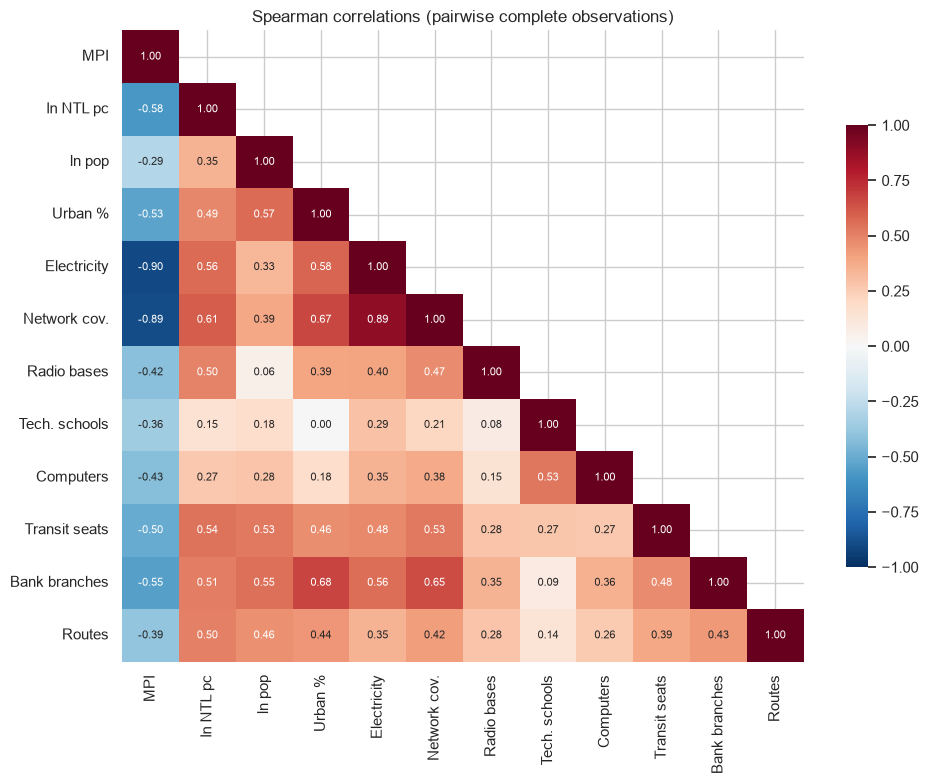

In [14]:
infra = ["urbano_2012", "sdg7_1_ec", "sdg9_c_mnc", "sdg9_c_drb", "sdg9_5_eutf", "sdg9_5_cd",
         "sdg11_2_samt", "sdg8_10_dbb", "sdg9_1_routes"]
gdf = gdf.merge(sdg[infra].reset_index(), on="geo_id")
corr_vars = ["sdg1_2_mpi", "ln_t400NTLpc", "ln_pop"] + infra
print("Missing values:", gdf[corr_vars].isna().sum()[lambda s: s > 0].to_dict())

short = {"sdg1_2_mpi": "MPI", "ln_t400NTLpc": "ln NTL pc", "ln_pop": "ln pop", "urbano_2012": "Urban %",
         "sdg7_1_ec": "Electricity", "sdg9_c_mnc": "Network cov.", "sdg9_c_drb": "Radio bases",
         "sdg9_5_eutf": "Tech. schools", "sdg9_5_cd": "Computers", "sdg11_2_samt": "Transit seats",
         "sdg8_10_dbb": "Bank branches", "sdg9_1_routes": "Routes"}
spearman = gdf[corr_vars].rename(columns=short).corr(method="spearman")
mask = np.triu(np.ones_like(spearman, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(spearman, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            annot_kws=dict(size=8), cbar_kws=dict(shrink=0.7), ax=ax)
ax.set_title("Spearman correlations (pairwise complete observations)")
plt.tight_layout()
plt.show()

In [15]:
with_mpi = pd.DataFrame({
    "pearson": gdf[corr_vars].corr()["sdg1_2_mpi"],
    "spearman": gdf[corr_vars].corr(method="spearman")["sdg1_2_mpi"],
    "n": gdf[corr_vars].notna().sum(),
}).drop("sdg1_2_mpi")
with_mpi.index = with_mpi.index.map(lambda v: f"{short[v]} ({v})")
with_mpi.sort_values("spearman").round(3)

,pearson,spearman,n
Electricity (sdg7_1_ec),-0.889,-0.905,339
Network cov. (sdg9_c_mnc),-0.879,-0.894,339
ln NTL pc (ln_t400NTLpc),-0.536,-0.581,339
Bank branches (sdg8_10_dbb),-0.493,-0.550,339
Urban % (urbano_2012),-0.543,-0.533,339
Transit seats (sdg11_2_samt),-0.274,-0.501,339
Computers (sdg9_5_cd),-0.288,-0.428,339
Radio bases (sdg9_c_drb),-0.375,-0.421,339
Routes (sdg9_1_routes),-0.390,-0.393,339
Tech. schools (sdg9_5_eutf),-0.287,-0.357,323


Every indicator correlates negatively with poverty: better-connected municipalities are less poor. The ranking (Spearman, robust to the skewed indicators):

- **Electricity coverage** (−0.91) and **fixed and mobile network coverage** (−0.89), both from the 2012 census, are near mirror images of poverty. Part of this is mechanical, since census-based poverty measures count deprivations in household services. They are also strongly correlated with each other (0.89).
- **Night-time lights** (−0.58), **bank branches** (−0.55), **urbanization** (−0.53) and **mass-transit seats** (−0.50) come next. For transit seats the Pearson correlation is only −0.27: the relation is monotonic but far from linear, driven by a few municipalities with very high values.
- The school-technology indicators of 2016 (computers delivered, −0.43; schools with technological floors, −0.36), radio bases (−0.42) and primary routes (−0.39) are weaker.
- **Population** is the weakest (−0.29), as section 2.3 showed.

To put these in context, here are the indicators of the whole Atlas most strongly associated with poverty (Spearman), excluding the poverty measures and the gender parity in the MPI, which share its ingredients:

In [16]:
others = sdg.drop(columns=["year", "mun_id", "sdg1_2_mpi", "sdg1_1_ubn", "sdg5_1_gpmpi"], errors="ignore")
rank = (others.corrwith(sdg["sdg1_2_mpi"], method="spearman").rename("spearman").to_frame()
        .assign(description=lambda d: d.index.map(labels),
                year=lambda d: d.index.map(ref_year))
        .dropna(subset=["spearman"]))
rank = rank.reindex(rank["spearman"].abs().sort_values(ascending=False).index)
rank.head(12).round(3)

,spearman,description,year
sdg7_1_ec,-0.905,Electricity coverage (%),2012
sdg9_c_mnc,-0.894,Households with a phone (%),2012
index_sdg7,-0.883,Clean energy index (0-100),2016
index_sdg1,-0.868,No poverty index (0-100),2016
sdg7_1_cce,-0.837,Clean cooking energy (% of households),2012
sdg2_2_cmc,0.782,Child chronic malnutrition (%),2016
sdg6_1_dwc,-0.754,Drinking water coverage (%),2017
sdg1_4_abs,-0.712,Access to 3 basic services (% of households),2012
index_sdg9,-0.699,Industry and infrastructure index (0-100),2019
sdg2_2_oww,-0.694,Obesity in women aged 15-49 (%),2016


Household energy and services dominate: electricity coverage, network coverage and clean cooking energy (all 2012), drinking water (2017) and access to the three basic services (2012). Chronic child malnutrition (2016, +0.78), extreme energy poverty (2016, +0.64) and climate-change vulnerability (2015, +0.57) rise with poverty. Obesity in women (−0.69), residential electricity consumption (−0.68) and CO₂ emissions from energy per capita (−0.64) are higher in the less poor, more urban municipalities.

## 3. Maps

Box-plot breaks flag the municipalities beyond the whiskers (1.5 × IQR); Fisher–Jenks natural breaks group similar values.

In [17]:
print(mc.BoxPlot(gdf["sdg1_2_mpi"]))
print(mc.FisherJenks(gdf["sdg1_2_mpi"], k=3))

BoxPlot

   Interval      Count
----------------------
( -inf, -0.10] |     0
(-0.10,  0.10] |    85
( 0.10,  0.17] |    87
( 0.17,  0.24] |    83
( 0.24,  0.45] |    81
( 0.45,  0.52] |     3
FisherJenks

  Interval     Count
--------------------
[0.01, 0.15] |   146
(0.15, 0.28] |   148
(0.28, 0.52] |    45


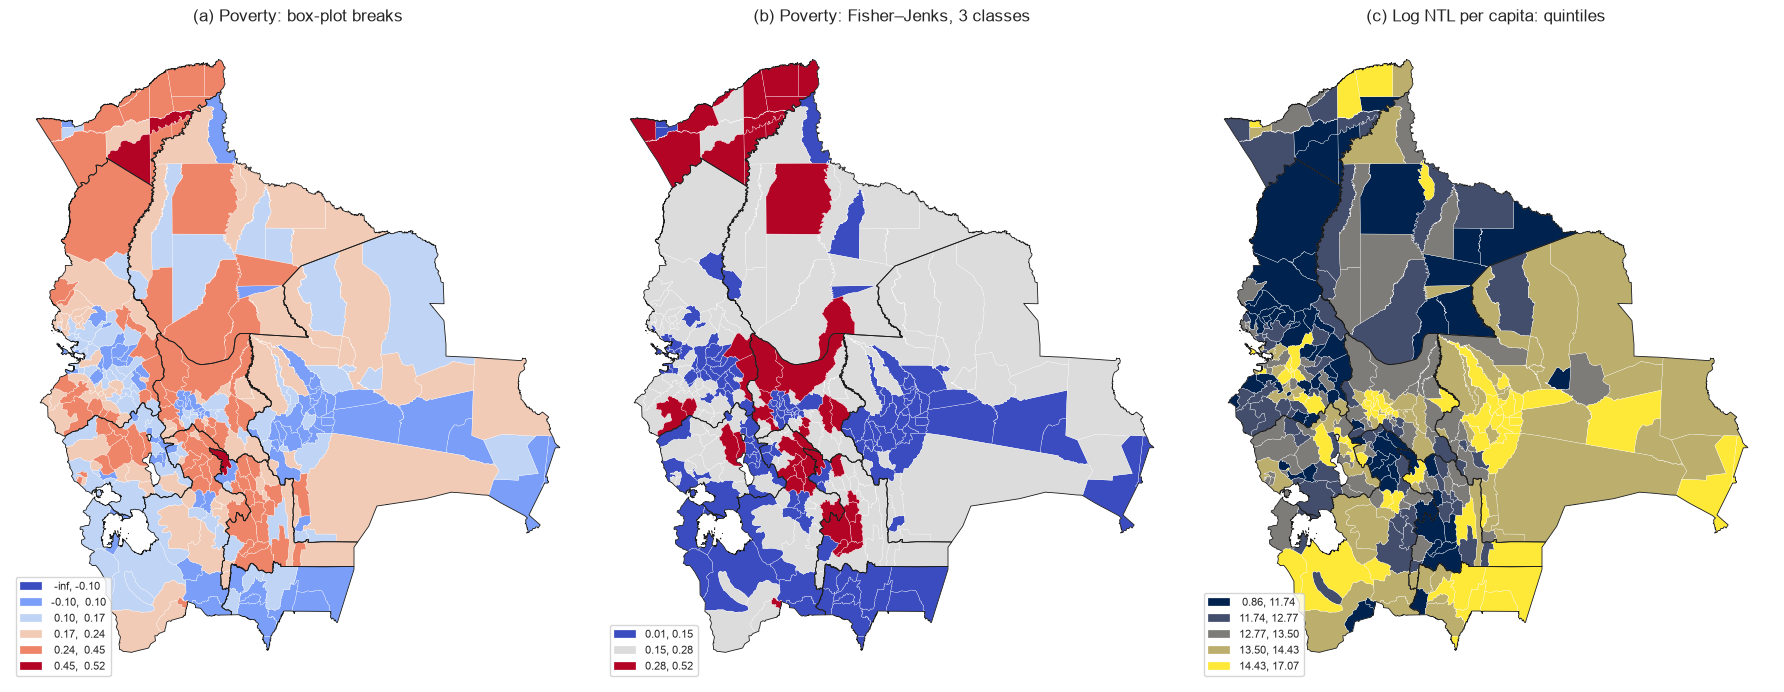

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
specs = [("sdg1_2_mpi", "BoxPlot", {}, "coolwarm", "(a) Poverty: box-plot breaks"),
         ("sdg1_2_mpi", "FisherJenks", {"k": 3}, "coolwarm", "(b) Poverty: Fisher–Jenks, 3 classes"),
         ("ln_t400NTLpc", "Quantiles", {"k": 5}, "cividis", "(c) Log NTL per capita: quintiles")]
for ax, (col, scheme, kw, cmap, title) in zip(axes, specs):
    gdf.plot(column=col, scheme=scheme, classification_kwds=kw, cmap=cmap, edgecolor="white",
             linewidth=0.2, legend=True, ax=ax,
             legend_kwds=dict(loc="lower left", fontsize=8, fmt="{:.2f}"))
    dep_lines.boundary.plot(ax=ax, color="k", linewidth=0.6)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

The box-plot rule finds no low outliers (the lower whisker is below zero) and three high outliers above 0.45: El Sena and San Pedro in Pando and Poroma in Chuquisaca. Fisher–Jenks puts 146 municipalities in a low class (up to 0.15), 148 in a middle class (0.15–0.28) and 45 in a high class (0.28–0.52).

Poverty is not scattered at random. The high class concentrates in two regions: the northern Amazon (Pando, northern La Paz and Beni) and the Andean valleys where Chuquisaca, Potosí and Cochabamba meet. Low poverty covers the Santa Cruz lowlands, Tarija, the south-western Altiplano and the metropolitan areas. The lights map is close to a negative image of the poverty map: dark in the north and in the central-southern valleys, bright in Santa Cruz, the south and the urban corridors. The next section measures these patterns formally.

## 4. Spatial dependence

- To what extent is a municipality's poverty similar to that of its neighbours?
- Is there an overall pattern of clustering?
- Where are the statistically significant clusters and spatial outliers?
- Do poor municipalities sit next to dark (or bright) ones?

### 4.1 Spatial weights

Each municipality's neighbours are its 6 nearest municipalities (by centroid), as in the original notebook. *k*-nearest neighbours give every unit the same number of neighbours and no islands; the weights are row-standardized, so the spatial lag is the neighbours' average.

n = 339, neighbours per unit = 6, asymmetric links: True


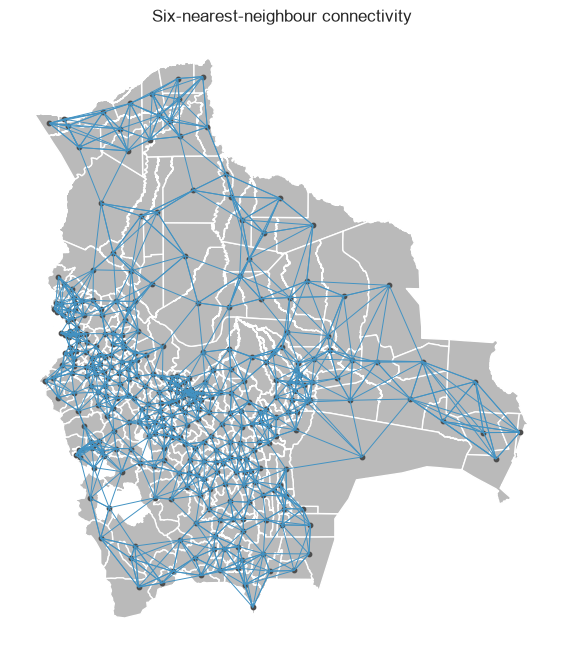

In [19]:
W = weights.KNN.from_dataframe(gdf, k=6)
W.transform = "r"
print(f"n = {W.n}, neighbours per unit = {W.mean_neighbors:.0f}, asymmetric links: {W.asymmetries != []}")

fig, ax = plt.subplots(figsize=(8, 8))
plot_spatial_weights(W, gdf, ax=ax)
ax.set_title("Six-nearest-neighbour connectivity")
plt.show()

### 4.2 Global spatial autocorrelation

In [20]:
gdf["W_mpi"] = weights.lag_spatial(W, gdf["sdg1_2_mpi"])
moran_vars = ["sdg1_2_mpi", "ln_t400NTLpc", "ln_pop", "urbano_2012", "sdg9_c_mnc", "sdg7_1_ec"]
rows = []
for v in moran_vars:
    m = Moran(gdf[v], W, permutations=999)
    rows.append({"variable": f"{short[v]} ({v})", "Moran's I": m.I, "E[I]": m.EI, "z (sim)": m.z_sim,
                 "p (sim)": m.p_sim})
moran_table = pd.DataFrame(rows).set_index("variable").round(3)
moran_table

,Moran's I,E[I],z (sim),p (sim)
variable,,,,
MPI (sdg1_2_mpi),0.457,-0.003,15.252,0.001
ln NTL pc (ln_t400NTLpc),0.324,-0.003,11.328,0.001
ln pop (ln_pop),0.371,-0.003,12.469,0.001
Urban % (urbano_2012),0.310,-0.003,11.274,0.001
Network cov. (sdg9_c_mnc),0.419,-0.003,14.470,0.001
Electricity (sdg7_1_ec),0.416,-0.003,14.059,0.001


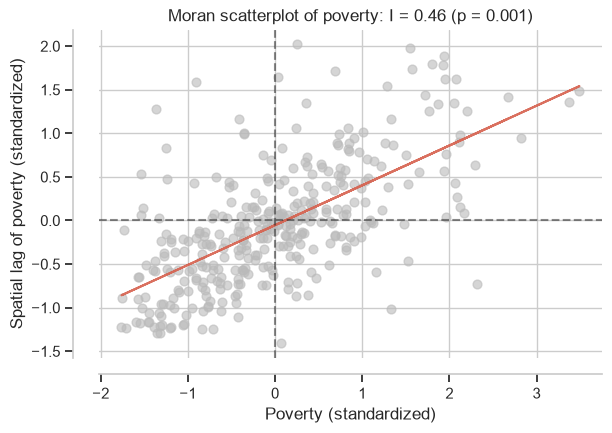

In [21]:
mi = Moran(gdf["sdg1_2_mpi"], W, permutations=999)
fig, ax = plt.subplots(figsize=(6.5, 6))
moran_scatterplot(mi, aspect_equal=True, zstandard=True, ax=ax)
ax.set(xlabel="Poverty (standardized)", ylabel="Spatial lag of poverty (standardized)",
       title=f"Moran scatterplot of poverty: I = {mi.I:.2f} (p = {mi.p_sim:.3f})")
plt.show()

Poverty is strongly and significantly clustered: Moran's I is 0.46, far above its expected value under spatial randomness (−0.003), with a pseudo p-value of 0.001 (the smallest possible with 999 permutations). It is the most clustered of the six variables. Network coverage (0.42), electricity coverage (0.42), log population (0.37), night-time lights (0.33) and urbanization (0.31) are also significantly clustered. In the scatterplot most municipalities fall in the High-High and Low-Low quadrants: poor municipalities have poor neighbours, and less poor ones less poor neighbours.

### 4.3 Local spatial autocorrelation (LISA)

The local Moran's I splits the global statistic into one value per municipality. With 999 permutations and a 10% significance level (as in the original):

- **High-High**: poor municipalities surrounded by poor neighbours (poverty hot spots)
- **Low-Low**: less poor municipalities surrounded by less poor neighbours (cold spots)
- **High-Low** / **Low-High**: spatial outliers

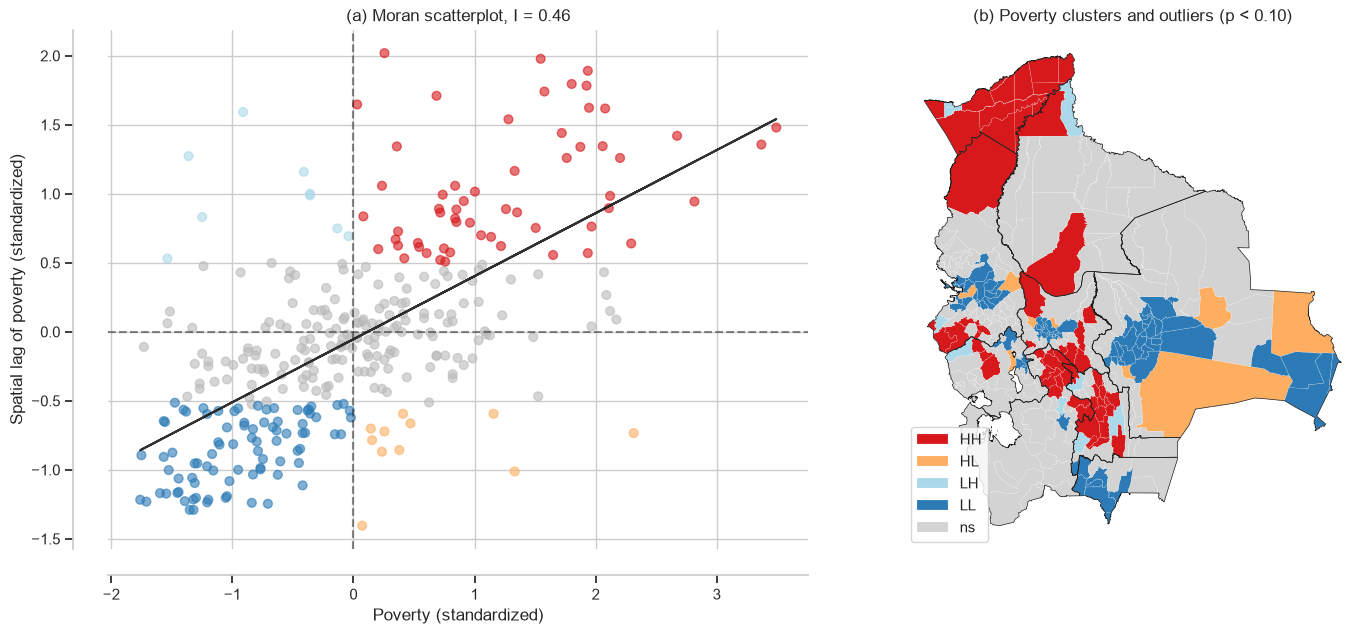

lisa_mpi,High-High,High-Low,Low-High,Low-Low,Not significant,All
department,,,,,,
Beni,2,0,1,0,16,19
Chuquisaca,15,0,3,1,10,29
Cochabamba,7,3,0,19,18,47
La Paz,7,3,1,23,53,87
Oruro,3,1,1,4,26,35
Pando,13,0,2,0,0,15
Potosí,11,0,1,1,27,40
Santa Cruz,0,4,0,30,22,56
Tarija,0,0,0,7,4,11


In [22]:
lisa = Moran_Local(gdf["sdg1_2_mpi"], W, permutations=999, seed=12345)
quad = {1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"}
P = 0.10
gdf["lisa_mpi"] = np.where(lisa.p_sim < P, pd.Series(lisa.q).map(quad), "Not significant")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
moran_scatterplot(lisa, p=P, aspect_equal=False, zstandard=True, ax=axes[0])
axes[0].set(xlabel="Poverty (standardized)", ylabel="Spatial lag of poverty (standardized)",
            title=f"(a) Moran scatterplot, I = {mi.I:.2f}")
lisa_cluster(lisa, gdf, p=P, ax=axes[1], legend_kwds=dict(loc="lower left"))
dep_lines.boundary.plot(ax=axes[1], color="k", linewidth=0.5)
axes[1].set_title(f"(b) Poverty clusters and outliers (p < {P:.2f})")
plt.tight_layout()
plt.show()

pd.crosstab(gdf["department"], gdf["lisa_mpi"], margins=True)

In [23]:
for c in ["High-High", "Low-Low", "High-Low", "Low-High"]:
    sel = gdf.loc[gdf["lisa_mpi"] == c].sort_values("sdg1_2_mpi", ascending=(c in ["Low-Low", "Low-High"]))
    print(f"{c} ({len(sel)}): " + ", ".join(f"{n} ({d})" for n, d in zip(sel["name"].head(8), sel["department"].head(8))))

High-High (58): El Sena (Pando), San Pedro (Pando), Poroma (Chuquisaca), Azurduy (Chuquisaca), San Pedro de Buena Vista (Potosí), Incahuasi (Chuquisaca), Vila Vila (Cochabamba), Ckochas (Potosí)
Low-Low (85): Colcapirhua (Cochabamba), La Paz (La Paz), Santa Cruz de la Sierra (Santa Cruz), Punata (Cochabamba), Quillacollo (Cochabamba), Tarija (Tarija), El Alto (La Paz), Cliza (Cochabamba)
High-Low (11): El Choro (Oruro), Morochata (Cochabamba), La Asunta (La Paz), Postrer Valle (Santa Cruz), San Miguel de Velasco (Santa Cruz), Tito Yupanqui (La Paz), Charagua (Santa Cruz), Cuchumuela (Cochabamba)
Low-High (9): Potosí (Potosí), Sucre (Chuquisaca), Cobija (Pando), Guayaramerín (Beni), Porvenir (Pando), Curahuara de Carangas (Oruro), Camargo (Chuquisaca), Monteagudo (Chuquisaca)


Of the 339 municipalities, 164 are significant at 10%: 58 High-High, 86 Low-Low, 11 High-Low and 9 Low-High.

- **Hot spots (High-High)** form two blocks. In the north, 13 of Pando's 15 municipalities are hot spots (all 15 are significant). In the south, the hot spots are rural municipalities of Chuquisaca (15), Potosí (11) and Cochabamba (7), with the poorest municipalities of the country: El Sena, San Pedro, Poroma, Azurduy, San Pedro de Buena Vista.
- **Cold spots (Low-Low)** are the lowlands of Santa Cruz (30), La Paz (23), around La Paz–El Alto, the Cochabamba valley (19) and Tarija (7).
- **Low-High outliers** are less poor towns in poor surroundings, mostly urban centres: the cities of Potosí, Sucre and Cobija, Guayaramerín, Porvenir, Camargo and Monteagudo.
- **High-Low outliers** are poor municipalities in less poor surroundings, for instance El Choro (Oruro), Morochata (Cochabamba), La Asunta (La Paz) and Charagua and San Miguel de Velasco (Santa Cruz).

### 4.4 Bivariate spatial association: poverty and neighbours' lights

The bivariate Moran's I relates a municipality's poverty to the **average night-time lights of its neighbours**. Its local version classifies each municipality by its own poverty (first word) and its neighbours' lights (second word): *High-Low* means a poor municipality in a dark neighbourhood, *Low-High* a less poor one in a bright neighbourhood.

Bivariate Moran's I (poverty vs neighbours' lights) = -0.249, p (sim) = 0.001
For reference, the correlation with own lights = -0.536


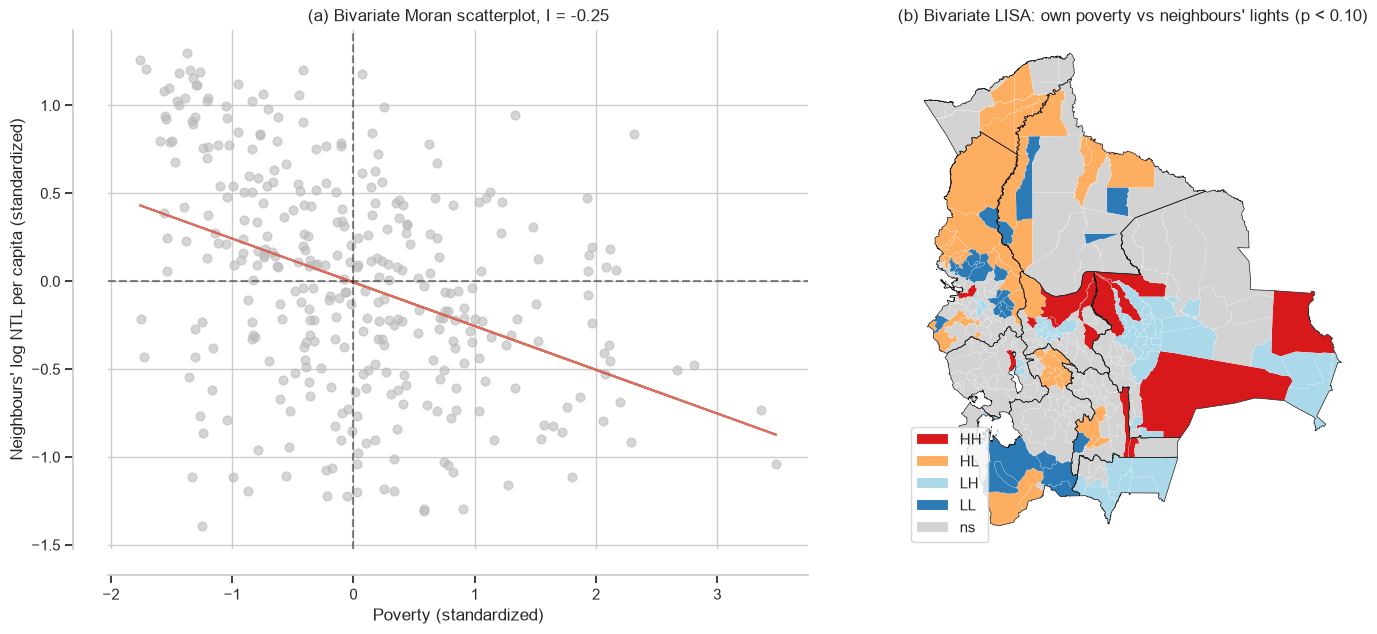

lisa_bv
Not significant    185
Low-High            63
High-Low            48
Low-Low             28
High-High           15
Name: count, dtype: int64

In [24]:
x, y = gdf["sdg1_2_mpi"].values, gdf["ln_t400NTLpc"].values
bv = Moran_BV(x, y, W, permutations=999)
r_own = np.corrcoef(x, y)[0, 1]
print(f"Bivariate Moran's I (poverty vs neighbours' lights) = {bv.I:.3f}, p (sim) = {bv.p_sim:.3f}")
print(f"For reference, the correlation with own lights = {r_own:.3f}")

lisa_bv = Moran_Local_BV(x, y, W, permutations=999, seed=12345)
gdf["lisa_bv"] = np.where(lisa_bv.p_sim < P, pd.Series(lisa_bv.q).map(quad), "Not significant")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
moran_scatterplot(bv, aspect_equal=False, ax=axes[0])
axes[0].set(xlabel="Poverty (standardized)", ylabel="Neighbours' log NTL per capita (standardized)",
            title=f"(a) Bivariate Moran scatterplot, I = {bv.I:.2f}")
lisa_cluster(lisa_bv, gdf, p=P, ax=axes[1], legend_kwds=dict(loc="lower left"))
dep_lines.boundary.plot(ax=axes[1], color="k", linewidth=0.5)
axes[1].set_title(f"(b) Bivariate LISA: own poverty vs neighbours' lights (p < {P:.2f})")
plt.tight_layout()
plt.show()

gdf["lisa_bv"].value_counts()

In [25]:
pd.crosstab(gdf["lisa_mpi"], gdf["lisa_bv"], margins=True)

lisa_bv,High-High,High-Low,Low-High,Low-Low,Not significant,All
lisa_mpi,,,,,,
High-High,0,26,0,0,32,58
High-Low,7,1,0,0,3,11
Low-High,0,0,0,2,7,9
Low-Low,0,0,52,3,30,85
Not significant,8,21,11,23,113,176
All,15,48,63,28,185,339


The bivariate Moran's I is −0.25 (p = 0.001): poor municipalities tend to have dark neighbours. The association is weaker than with a municipality's own lights (correlation −0.54), as expected, but clearly significant.

The bivariate LISA flags 154 municipalities at 10%, dominated by the two "expected" combinations:

- **Low-High** (63): less poor municipalities in bright neighbourhoods, in Santa Cruz (29), the Cochabamba valley (19) and Tarija (8).
- **High-Low** (48): poor municipalities in dark neighbourhoods, mostly in La Paz (20, e.g. Ixiamas in the north), Potosí (10), Pando (7), Beni (6) and Chuquisaca (4).
- **Low-Low** (27): less poor municipalities with dark neighbours, mainly in La Paz (18; e.g. Caranavi, Quime, Santiago de Machaca).
- **High-High** (16): poor municipalities with bright neighbours, for example the Chapare in Cochabamba (Villa Tunari, Chimoré, Pojo) and five municipalities of Santa Cruz.

The cross-tabulation links the two analyses. Of the 58 poverty hot spots, 26 are poor municipalities in dark neighbourhoods; of the 86 cold spots, 52 sit in bright neighbourhoods. Most of the other hot and cold spots (32 and 31) are not significant in the bivariate map.

## 5. Spatial inequality

How unequal is poverty across municipalities, and how much of it lies between departments? The Gini and Theil indices need non-negative levels, so night-time lights enter here as **lights per capita in levels**, exp(`ln_t400NTLpc`), not in logs.

The Theil index splits exactly into inequality *between* department means and *within* departments. The spatial Gini (Rey and Smith, 2013) splits the Gini's sum of absolute differences into neighbour pairs and all other pairs: if neighbours are more alike than random pairs, the neighbour pairs contribute less than their share of all pairs. The p-value comes from 999 random permutations of the values over the map.

In [26]:
gdf["NTLpc"] = np.exp(gdf["ln_t400NTLpc"])
ineq = []
for v, lab in [("sdg1_2_mpi", "Poverty (MPI)"), ("NTLpc", "NTL per capita (levels)")]:
    vals = gdf[v].values
    theil = inequality.theil.Theil(vals).T
    td = inequality.theil.TheilD(vals, gdf["department"].values)
    np.random.seed(12345)
    gs = Gini_Spatial(vals, W, permutations=999)
    ineq.append({"variable": lab, "Gini": inequality.gini.Gini(vals).g, "Theil": theil,
                 "Theil between departments (%)": 100 * float(td.bg[0]) / theil,
                 "Theil within departments (%)": 100 * float(td.wg[0]) / theil,
                 "Gini from neighbour pairs (%)": 100 * gs.wg / gs.dtotal,
                 "spatial Gini p (sim)": gs.p_sim})
print(f"Neighbour pairs are {100 * W.n * 6 / (W.n * (W.n - 1)):.2f}% of all pairs")
pd.DataFrame(ineq).set_index("variable").round(3).T

Neighbour pairs are 1.78% of all pairs


variable,Poverty (MPI),NTL per capita (levels)
Gini,0.306,0.634
Theil,0.154,0.770
Theil between departments (%),23.841,21.917
Theil within departments (%),76.159,78.083
Gini from neighbour pairs (%),1.249,1.321
spatial Gini p (sim),0.001,0.001


Municipal poverty has a Gini of 0.31 and a Theil of 0.15. Only 24% of the Theil index is inequality *between* departments; 76% is *within* them. This matches the overlapping boxes of section 2.2: departments differ, but most of the inequality lies between municipalities of the same department.

Night-time lights per capita are far more unequal (Gini 0.63, Theil 0.77), with a similar split (22% between, 78% within).

The spatial Gini shows the clustering from another angle. Neighbour pairs are 1.78% of all pairs but contribute only 1.25% of the Gini of poverty and 1.32% of that of lights. In both cases the permutation p-value is 0.001: neighbouring municipalities are much more alike than random pairs.

## 6. Spatial heterogeneity: geographically weighted regression

The global regression of section 2.4 imposes one slope on all municipalities. A geographically weighted regression (GWR) estimates a local regression around every municipality, weighting neighbours by distance with an adaptive bisquare kernel whose bandwidth (the number of neighbours) is chosen by AICc. Coordinates are centroids in the equal-area projection (km).

In [27]:
cent = gdf.geometry.centroid
coords = np.column_stack([cent.x, cent.y]) / 1000
y_gwr = gdf["sdg1_2_mpi"].values.reshape(-1, 1)
X_gwr = gdf[["ln_t400NTLpc"]].values

selector = Sel_BW(coords, y_gwr, X_gwr)
bw = selector.search(criterion="AICc")
gwr = GWR(coords, y_gwr, X_gwr, bw).fit()
print(f"Bandwidth: {bw:.0f} nearest neighbours")
print(f"Global OLS: R² = {ols_ntl.rsquared:.3f}, AIC = {ols_ntl.aic:.1f}")
print(f"GWR:        R² = {gwr.R2:.3f}, AIC = {gwr.aic:.1f}, AICc = {gwr.aicc:.1f}")

Bandwidth: 46 nearest neighbours
Global OLS: R² = 0.287, AIC = -726.0
GWR:        R² = 0.624, AIC = -869.7, AICc = -859.4


In [28]:
gdf["gwr_slope"] = gwr.params[:, 1]
gdf["gwr_R2"] = gwr.localR2.ravel()
sig = gwr.filter_tvals()[:, 1] != 0          # t-values corrected for multiple testing
print(gdf["gwr_slope"].describe().round(3))
print(f"Significant slopes (corrected): {sig.sum()} of {len(sig)}; "
      f"negative: {(gdf.loc[sig, 'gwr_slope'] < 0).sum()}, positive: {(gdf.loc[sig, 'gwr_slope'] > 0).sum()}")

count    339.000
mean      -0.038
std        0.021
min       -0.095
25%       -0.055
50%       -0.030
75%       -0.020
max       -0.004
Name: gwr_slope, dtype: float64
Significant slopes (corrected): 194 of 339; negative: 194, positive: 0


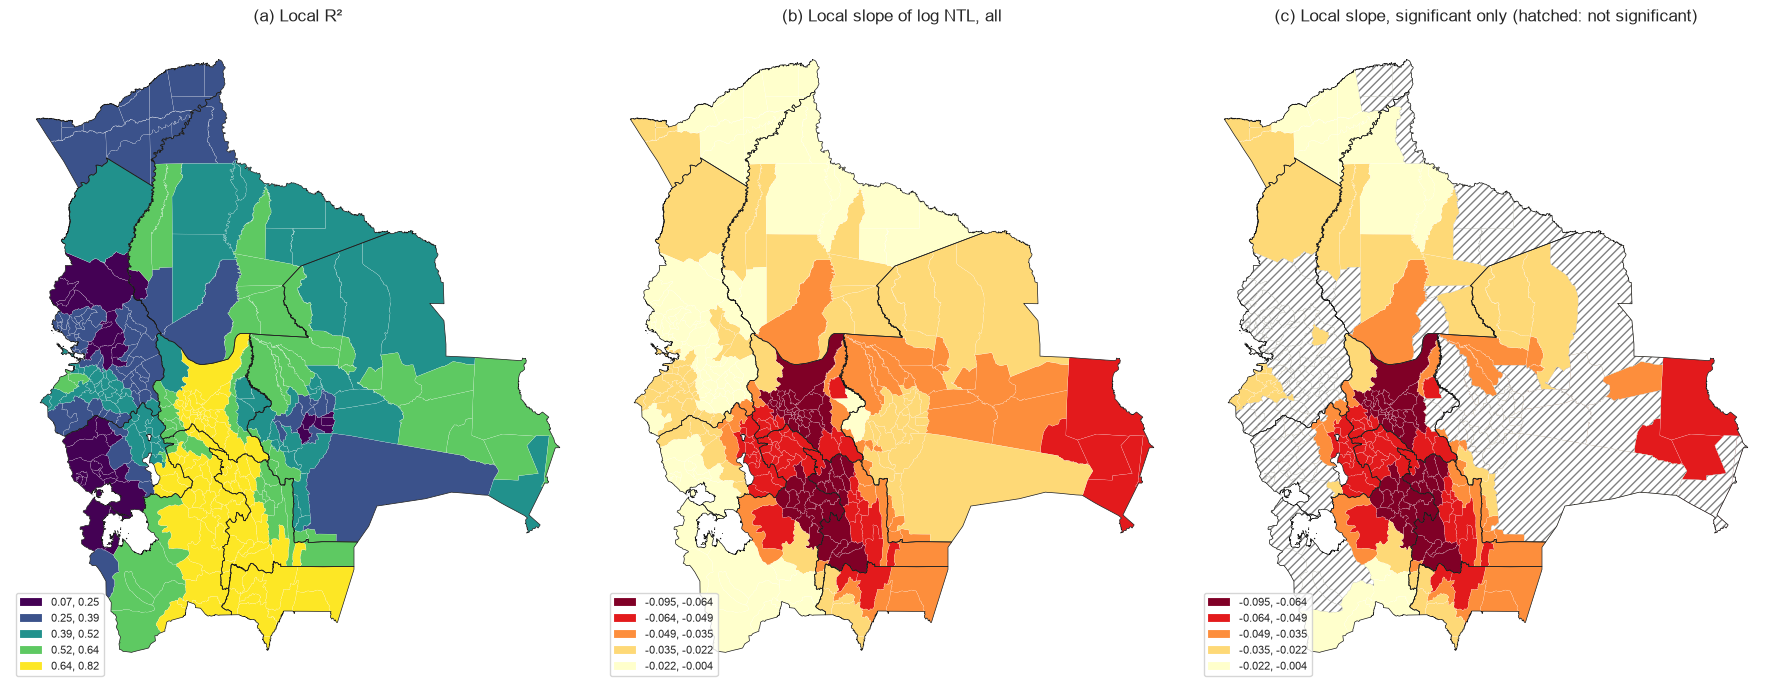

,gwr_slope,gwr_R2
department,,
Cochabamba,-0.065,0.652
Chuquisaca,-0.059,0.698
Potosí,-0.049,0.666
Tarija,-0.037,0.755
Santa Cruz,-0.036,0.465
Oruro,-0.031,0.317
La Paz,-0.021,0.369
Beni,-0.021,0.459
Pando,-0.020,0.284


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
gdf.plot(column="gwr_R2", scheme="FisherJenks", k=5, cmap="viridis", linewidth=0.1, edgecolor="white",
         legend=True, legend_kwds=dict(loc="lower left", fontsize=8, fmt="{:.2f}"), ax=axes[0])
axes[0].set_title("(a) Local R²")
for ax, mask_sig, title in [(axes[1], np.ones(len(gdf), bool), "(b) Local slope of log NTL, all"),
                            (axes[2], sig, "(c) Local slope, significant only (hatched: not significant)")]:
    gdf.plot(column="gwr_slope", scheme="FisherJenks", k=5, cmap="YlOrRd_r", linewidth=0.1, edgecolor="white",
             legend=True, legend_kwds=dict(loc="lower left", fontsize=8, fmt="{:.3f}"), ax=ax)
    gdf[~mask_sig].plot(color="white", edgecolor="grey", hatch="////", linewidth=0.1, ax=ax)
    ax.set_title(title)
for ax in axes:
    dep_lines.boundary.plot(ax=ax, color="k", linewidth=0.5)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

gdf.groupby("department")[["gwr_slope", "gwr_R2"]].mean().round(3).sort_values("gwr_slope")

Letting the relationship vary over space improves the fit considerably. The AICc selects a bandwidth of 46 nearest neighbours, and the GWR raises the R² from 0.29 to 0.62, with a much lower AIC (−870 against −726), which penalizes the extra parameters.

All 339 local slopes are negative, from −0.095 to −0.004 (mean −0.038). After correcting for multiple testing, 194 are significant, all of them negative. More lights go with less poverty everywhere, but at different rates:

- The relationship is **steepest** in the central-southern Andean valleys, with department means of −0.065 in Cochabamba, −0.059 in Chuquisaca and −0.049 in Potosí. There the local R² is highest (0.65–0.82): lights are a good proxy for poverty.
- It is **flattest** in Pando, Beni and La Paz (about −0.02). On the western Altiplano of La Paz and Oruro the local R² falls below 0.25, and most slopes are not significant.

A single global slope therefore understates the link in the valleys and overstates it on the Altiplano. The `esda_heterogeneity` notebook adds a multiscale GWR (MGWR).

## 7. Summary

- **Level and spread.** In 2012 the municipal MPI averages 0.18 and ranges from 0.007 to 0.52. Pando and Chuquisaca are the poorest departments, Tarija and Santa Cruz the least poor, and the big cities the least poor municipalities.
- **Correlates.** Poverty falls with electricity and network coverage (Spearman about −0.9), night-time lights (−0.58), bank branches, urbanization and transit, and only weakly with population (−0.29). Lights alone explain 29% of its variation.
- **Clustering.** Poverty is strongly clustered (Moran's I = 0.46). There are hot spots in Pando and the Chuquisaca–Potosí–Cochabamba valleys, and cold spots in Santa Cruz, the La Paz–El Alto area, the Cochabamba valley and Tarija.
- **Neighbours' lights.** Poor municipalities tend to have dark neighbours (bivariate Moran's I = −0.25). Most hot spots are poor places in dark neighbourhoods and most cold spots less poor places in bright ones.
- **Inequality.** Three quarters of the inequality in poverty lies within departments, not between them.
- **Heterogeneity.** The lights–poverty slope is negative everywhere but its size varies more than twentyfold. It is steepest and most informative in the central-southern valleys and weakest on the Altiplano.